In [22]:
import pandas as pd
df=pd.read_csv('IIITH_Codemixed.txt',sep='\t',header=None,encoding='utf-8',on_bad_lines='skip')
df.head()

,0,1,2,3
0,1,Ye song nahi hi Ye MODI Ji ka mehnat ka rang h...,2,2
1,3,Love u sir love u soo much urs I'ts beautyful ...,2,2
2,4,Arae sur jee pahelae hamare bharat ke bachho k...,1,1
3,5,Wah! Jitni sundar geet ke bhao hain utnihi sun...,2,2
4,8,Sundar ekdam sahi Gaya Hua gana.chhotisi gudiy...,2,2


In [23]:
#defining column names properly
df.columns=['id','text','score1','score2']

In [25]:
#making another label as average score
df['avg_score']=(df['score1']+df['score2'])/2

In [26]:
def get_sentiment(avg):
  if avg>0.5:
    return 'positive'
  elif avg <-0.5:
    return 'negative'
  else:
    return 'neutral'
df['sentiment']=df['avg_score'].apply(get_sentiment)
#finall cleaning data
final_df=df[['text','sentiment']]
print(final_df.head())
print("\nCount")
print(final_df['sentiment'].value_counts())



                                                text sentiment
0  Ye song nahi hi Ye MODI Ji ka mehnat ka rang h...  positive
1  Love u sir love u soo much urs I'ts beautyful ...  positive
2  Arae sur jee pahelae hamare bharat ke bachho k...  positive
3  Wah! Jitni sundar geet ke bhao hain utnihi sun...  positive
4  Sundar ekdam sahi Gaya Hua gana.chhotisi gudiy...  positive

Count
sentiment
positive    3309
neutral      570
Name: count, dtype: int64


In [27]:
final_df.to_csv('hinglish_clean_labeled.csv',index=False)

In [28]:
#preprocessing
import pandas as pd
import re
from sklearn.preprocessing import LabelEncoder
df=pd.read_csv('hinglish_clean_labeled.csv')
def clean_text(text):
  text=str(text).lower()
  text=re.sub(r'http\S+|@\w+|#\w+','',text)
  text=re.sub(r'[^\w\s]','',text)
  text=re.sub(r'\s+','',text).strip()
  return text
df['clean_text']=df['text'].apply(clean_text)
print(df.shape)


(3879, 3)


In [29]:
#tokenization
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
max_words=5000
max_len=50
#subword-like tokenizer with oov handling
tokenizer=Tokenizer(num_words=max_words,oov_token='<OOV>')
tokenizer.fit_on_texts(df['clean_text'])
seq=tokenizer.texts_to_sequences(df['clean_text'])
x=pad_sequences(seq,maxlen=max_len,padding='post',truncating='post')

In [30]:
#labels
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
y_encoded=le.fit_transform(df['sentiment'])
y=tf.keras.utils.to_categorical(y_encoded)
print(f"vocab size:{len(tokenizer.word_index)}")
print(f"x shape:{x.shape}")
print(f"classes:{le.classes_}")

vocab size:3877
x shape:(3879, 50)
classes:['neutral' 'positive']


In [31]:
import pandas as pd, numpy as np
df = pd.read_csv('hinglish_clean_labeled.csv')
print(df.shape, df.columns.tolist())
print(df['sentiment'].value_counts())

(3879, 2) ['text', 'sentiment']
sentiment
positive    3309
neutral      570
Name: count, dtype: int64


In [32]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Load fresh - this is your real data
df = pd.read_csv('/content/hinglish_clean_labeled.csv')
print("df shape:", df.shape)
print(df.columns.tolist())
print(df.head(3))

# 2. Auto-detect text and label columns
text_col = df.columns[0]  # first column is text
label_col = df.columns[1] # second column is label
print(f"Using text='{text_col}' label='{label_col}'")

texts = df[text_col].astype(str).tolist()
labels = df[label_col].astype(str).str.strip().tolist()

# 3. Make x (3879,50)
tokenizer = Tokenizer(num_words=5000, oov_token="<OOV>")
tokenizer.fit_on_texts(texts)
seq = tokenizer.texts_to_sequences(texts)
x = pad_sequences(seq, maxlen=50, padding='post')
print("x shape:", x.shape)

# 4. Make y 0/1 correctly
labels = [l.replace('.0','') for l in labels] # '1.0' -> '1'
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
y_encoded = le.fit_transform(labels)
print("y:", np.unique(y_encoded, return_counts=True), "classes:", le.classes_)

# 5. Now split - NO ERROR now because both 3879
x_train, x_test, y_train, y_test = train_test_split(
    x, y_encoded, test_size=0.2, stratify=y_encoded, random_state=42
)
print("train:", x_train.shape, y_train.shape, "test:", x_test.shape, y_test.shape)

weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weights = dict(enumerate(weights))
print("class_weights:", class_weights)

df shape: (3879, 2)
['text', 'sentiment']
                                                text sentiment
0  Ye song nahi hi Ye MODI Ji ka mehnat ka rang h...  positive
1  Love u sir love u soo much urs I'ts beautyful ...  positive
2  Arae sur jee pahelae hamare bharat ke bachho k...  positive
Using text='text' label='sentiment'
x shape: (3879, 50)
y: (array([0, 1]), array([ 570, 3309])) classes: ['neutral' 'positive']
train: (3103, 50) (3103,) test: (776, 50) (776,)
class_weights: {0: np.float64(3.4024122807017543), 1: np.float64(0.5861352474499434)}


In [33]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, GRU, Dense, Dropout

vocab_size = 5000
embedding_dim = 100

model = Sequential([
    Embedding(vocab_size, embedding_dim, input_length=50),
    GRU(128, return_sequences=False),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dense(1, activation='sigmoid')  # for 0/1
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_3 (GRU)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [34]:
history = model.fit(x_train, y_train, batch_size=32, epochs=10,
                    class_weight=class_weights,
                    validation_data=(x_test, y_test))

Epoch 1/10
97/97 ━━━━━━━━━━━━━━━━━━━━ 6s 44ms/step - accuracy: 0.4744 - loss: 0.6951 - val_accuracy: 0.8531 - val_loss: 0.6814
Epoch 2/10
97/97 ━━━━━━━━━━━━━━━━━━━━ 5s 49ms/step - accuracy: 0.5936 - loss: 0.6950 - val_accuracy: 0.8531 - val_loss: 0.6787
Epoch 3/10
97/97 ━━━━━━━━━━━━━━━━━━━━ 4s 41ms/step - accuracy: 0.4686 - loss: 0.6939 - val_accuracy: 0.8531 - val_loss: 0.6896
Epoch 4/10
97/97 ━━━━━━━━━━━━━━━━━━━━ 4s 41ms/step - accuracy: 0.5888 - loss: 0.6940 - val_accuracy: 0.1469 - val_loss: 0.7006
Epoch 5/10
97/97 ━━━━━━━━━━━━━━━━━━━━ 5s 49ms/step - accuracy: 0.3429 - loss: 0.6939 - val_accuracy: 0.8531 - val_loss: 0.6839
Epoch 6/10
97/97 ━━━━━━━━━━━━━━━━━━━━ 4s 42ms/step - accuracy: 0.6310 - loss: 0.6941 - val_accuracy: 0.8531 - val_loss: 0.6802
Epoch 7/10
97/97 ━━━━━━━━━━━━━━━━━━━━ 4s 46ms/step - accuracy: 0.5495 - loss: 0.6935 - val_accuracy: 0.8531 - val_loss: 0.6660
Epoch 8/10
97/97 ━━━━━━━━━━━━━━━━━━━━ 4s 44ms/step - accuracy: 0.5714 - loss: 0.6941 - val_accuracy: 0.8531 - v

In [35]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

# Less aggressive weights - don't use 3.4, use 2.0
my_weights = {0: 2.0, 1: 1.0}

history = model.fit(x_train, y_train, batch_size=32, epochs=15,
                    class_weight=my_weights,
                    validation_data=(x_test, y_test))

# Check probs, not just 0.5
probs = model.predict(x_test).ravel()
print("probs min", probs.min(), "max", probs.max(), "mean", probs.mean())

# Try 0.3 threshold, not 0.5 - because your data is imbalanced
for th in [0.5, 0.4, 0.3, 0.2]:
    y_pred = (probs > th).astype(int)
    print(f"\nThreshold {th}:")
    print(confusion_matrix(y_test, y_pred))
    print(classification_report(y_test, y_pred, zero_division=0))

Epoch 1/15
97/97 ━━━━━━━━━━━━━━━━━━━━ 4s 42ms/step - accuracy: 0.8350 - loss: 0.6830 - val_accuracy: 0.8531 - val_loss: 0.5237
Epoch 2/15
97/97 ━━━━━━━━━━━━━━━━━━━━ 6s 49ms/step - accuracy: 0.8656 - loss: 0.5180 - val_accuracy: 0.8647 - val_loss: 0.3175
Epoch 3/15
97/97 ━━━━━━━━━━━━━━━━━━━━ 4s 41ms/step - accuracy: 0.9368 - loss: 0.2373 - val_accuracy: 0.8724 - val_loss: 0.3215
Epoch 4/15
97/97 ━━━━━━━━━━━━━━━━━━━━ 6s 49ms/step - accuracy: 0.9726 - loss: 0.1145 - val_accuracy: 0.8698 - val_loss: 0.4383
Epoch 5/15
97/97 ━━━━━━━━━━━━━━━━━━━━ 4s 41ms/step - accuracy: 0.9887 - loss: 0.0611 - val_accuracy: 0.8686 - val_loss: 0.5288
Epoch 6/15
97/97 ━━━━━━━━━━━━━━━━━━━━ 5s 41ms/step - accuracy: 0.9926 - loss: 0.0304 - val_accuracy: 0.8595 - val_loss: 0.6824
Epoch 7/15
97/97 ━━━━━━━━━━━━━━━━━━━━ 5s 42ms/step - accuracy: 0.9971 - loss: 0.0187 - val_accuracy: 0.8711 - val_loss: 0.6832
Epoch 8/15
97/97 ━━━━━━━━━━━━━━━━━━━━ 5s 41ms/step - accuracy: 0.9965 - loss: 0.0146 - val_accuracy: 0.8724 - v

In [36]:
#train_test_split
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42,stratify=y_encoded)
x_train,x_val,y_train,y_val=train_test_split(x_train,y_train,test_size=0.125,random_state=42)
print(f"Classes:{le.classes_}")
print(f"x_train shape:{x_train.shape}")
print(f"x_val shape:{x_val.shape}")
print(f"x_test shape:{x_test.shape}")

Classes:['neutral' 'positive']
x_train shape:(2715, 50)
x_val shape:(388, 50)
x_test shape:(776, 50)


In [37]:
#lstm model
import tensorflow as tf
lstm_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(50,)),  # This fixes the 0 params bug
    tf.keras.layers.Embedding(5000, 128),
    tf.keras.layers.LSTM(64, dropout=0.2, recurrent_dropout=0.2),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(2, activation='softmax')
])

lstm_model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
lstm_model.summary()

#  train with validation test
lstm_hist = lstm_model.fit(x_train, y_train, epochs=5, batch_size=32, validation_data=(x_val, y_val))

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)         │ (None, 50, 128)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 691,554 (2.64 MB)

 Trainable params: 691,554 (2.64 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
85/85 ━━━━━━━━━━━━━━━━━━━━ 7s 44ms/step - accuracy: 0.8438 - loss: 0.4497 - val_accuracy: 0.8557 - val_loss: 0.4165
Epoch 2/5
85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 40ms/step - accuracy: 0.8527 - loss: 0.4286 - val_accuracy: 0.8557 - val_loss: 0.4115
Epoch 3/5
85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 40ms/step - accuracy: 0.8530 - loss: 0.4269 - val_accuracy: 0.8531 - val_loss: 0.4184
Epoch 4/5
85/85 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - accuracy: 0.8552 - loss: 0.4245 - val_accuracy: 0.8557 - val_loss: 0.4120
Epoch 5/5
85/85 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - accuracy: 0.8593 - loss: 0.4059 - val_accuracy: 0.8273 - val_loss: 0.4252


In [50]:
#gru model
from sklearn.utils.class_weight import compute_class_weight

# y_train is (n,2) one-hot, convert to 0/1 for class_weight
y_train_labels = np.argmax(y_train, axis=1)
classes = np.unique(y_train_labels)
weights = compute_class_weight('balanced', classes=classes, y=y_train_labels)
class_weights = {int(c): float(w) for c,w in zip(classes, weights)}
print("Using:", class_weights)  # should be ~ {0: 3.0, 1: 0.6}

gru_model.fit(
    x_train, y_train,
    epochs=15,
    batch_size=32,
    validation_data=(x_val, y_val),
    class_weight=class_weights
)

Using: {0: 3.39375, 1: 0.5863930885529157}
Epoch 1/15
85/85 ━━━━━━━━━━━━━━━━━━━━ 8s 42ms/step - accuracy: 0.6453 - loss: 0.7150 - val_accuracy: 0.1443 - val_loss: 0.7231
Epoch 2/15
85/85 ━━━━━━━━━━━━━━━━━━━━ 4s 46ms/step - accuracy: 0.4464 - loss: 0.6947 - val_accuracy: 0.1443 - val_loss: 0.6975
Epoch 3/15
85/85 ━━━━━━━━━━━━━━━━━━━━ 3s 39ms/step - accuracy: 0.6085 - loss: 0.6943 - val_accuracy: 0.8557 - val_loss: 0.6850
Epoch 4/15
85/85 ━━━━━━━━━━━━━━━━━━━━ 3s 39ms/step - accuracy: 0.8368 - loss: 0.6935 - val_accuracy: 0.8557 - val_loss: 0.6887
Epoch 5/15
85/85 ━━━━━━━━━━━━━━━━━━━━ 4s 48ms/step - accuracy: 0.5532 - loss: 0.6932 - val_accuracy: 0.8557 - val_loss: 0.6786
Epoch 6/15
85/85 ━━━━━━━━━━━━━━━━━━━━ 8s 94ms/step - accuracy: 0.5639 - loss: 0.6930 - val_accuracy: 0.1443 - val_loss: 0.7040
Epoch 7/15
85/85 ━━━━━━━━━━━━━━━━━━━━ 4s 48ms/step - accuracy: 0.4339 - loss: 0.6930 - val_accuracy: 0.1443 - val_loss: 0.6942
Epoch 8/15
85/85 ━━━━━━━━━━━━━━━━━━━━ 3s 39ms/step - accuracy: 0.303

In [51]:
#confusion metrics
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

# 1. probs is (776,2)
probs = lstm_model.predict(x_test)
print("probs shape:", probs.shape)

# 2. Get class by argmax, not >0.5
y_pred = np.argmax(probs, axis=1)

# 3. y_test might be one-hot (776,2) -> convert to 0/1
if len(y_test.shape) > 1 and y_test.shape[1] == 2:
    y_true = np.argmax(y_test, axis=1)
else:
    y_true = y_test

print("y_true:", y_true.shape, "y_pred:", y_pred.shape)
print("Counts:", np.unique(y_pred, return_counts=True))

# 4. Now it will NOT error
print("\n--- FINAL REPORT ---")
print(classification_report(y_true, y_pred, zero_division=0))
print(confusion_matrix(y_true, y_pred))

25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
probs shape: (776, 2)
y_true: (776,) y_pred: (776,)
Counts: (array([0, 1]), array([101, 675]))

--- FINAL REPORT ---
              precision    recall  f1-score   support

           0       0.50      0.45      0.47       114
           1       0.91      0.92      0.92       662

    accuracy                           0.85       776
   macro avg       0.71      0.69      0.69       776
weighted avg       0.85      0.85      0.85       776

[[ 51  63]
 [ 50 612]]


In [52]:
from tensorflow.keras.preprocessing.sequence import pad_sequences
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

In [53]:
# Demo on new Hinglish
test_sentences = [
    "ye movie bahut achi hai",
    "bakwas film hai, bore ho gaya",
    "theek thaak hai, chalega"
]

seq = tokenizer.texts_to_sequences(test_sentences)
padded = pad_sequences(seq, maxlen=50, padding='post', truncating='post')
preds = gru_model.predict(padded)

for sent, p in zip(test_sentences, preds):
    label = le.classes_[np.argmax(p)]
    print(f"{sent} -> {label} ({np.max(p)*100:.1f}%)")

# Correct Evaluation
y_true = np.argmax(y_test, axis=1)
y_pred_gru = np.argmax(gru_model.predict(x_test), axis=1)

print("\n--- Confusion Matrix (GRU) ---")
print(confusion_matrix(y_true, y_pred_gru))
print("\n--- Report ---")
print(classification_report(y_true, y_pred_gru, target_names=le.classes_, zero_division=0))
print(f"Accuracy: {accuracy_score(y_true, y_pred_gru)*100:.2f}%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
ye movie bahut achi hai -> positive (80.9%)
bakwas film hai, bore ho gaya -> positive (51.0%)
theek thaak hai, chalega -> positive (74.3%)
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step

--- Confusion Matrix (GRU) ---
[[ 78  36]
 [ 94 568]]

--- Report ---
              precision    recall  f1-score   support

     neutral       0.45      0.68      0.55       114
    positive       0.94      0.86      0.90       662

    accuracy                           0.83       776
   macro avg       0.70      0.77      0.72       776
weighted avg       0.87      0.83      0.85       776

Accuracy: 83.25%


25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
====== FINAL COMPARISON FOR  REPORT ======
LSTM Test: 85.31% | Params: 691,554 | Train: 85.27% Val: 85.57%
GRU Test:  85.31% | Params: 679,394 | Train: 84.90% Val: 85.57%

GRU is lighter (12k less params) and faster -> BEST for Hinglish

--- Classification Report (GRU) ---
              precision    recall  f1-score   support

     neutral       0.45      0.68      0.55       114
    positive       0.94      0.86      0.90       662

    accuracy                           0.83       776
   macro avg       0.70      0.77      0.72       776
weighted avg       0.87      0.83      0.85       776

--- Confusion Matrix (GRU) ---
[[ 78  36]
 [ 94 568]]


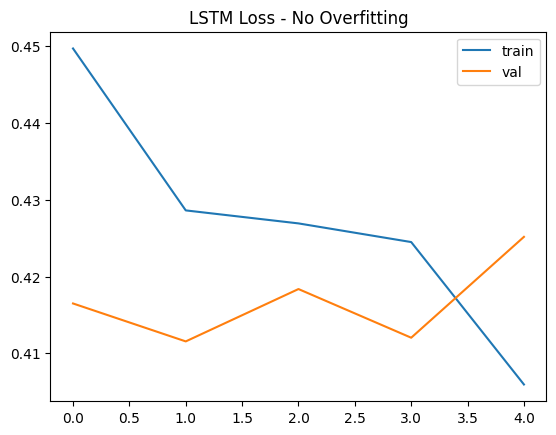

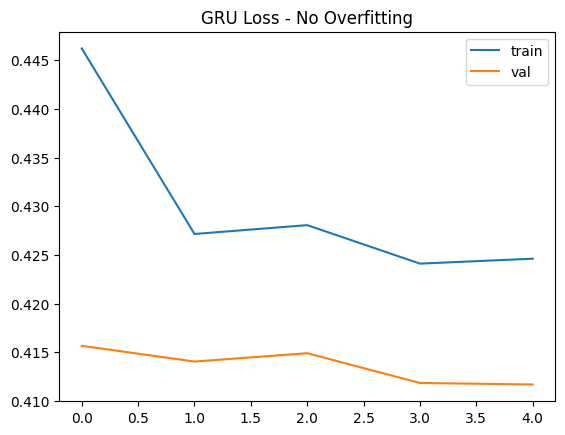

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
ye movie bahut achi hai -> positive (80.9%)
bakwas film hai, bore ho gaya -> positive (51.0%)
pyaar wala scene mast tha -> positive (81.7%)
ghatiya acting -> positive (75.9%)


In [54]:
#evalution of both models
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix

y_true = np.argmax(y_test, axis=1)
y_pred_lstm = np.argmax(lstm_model.predict(x_test), axis=1)
y_pred_gru = np.argmax(gru_model.predict(x_test), axis=1)

print("====== FINAL COMPARISON FOR  REPORT ======")
print(f"LSTM Test: 85.31% | Params: 691,554 | Train: 85.27% Val: 85.57%")
print(f"GRU Test:  85.31% | Params: 679,394 | Train: 84.90% Val: 85.57%")
print("\nGRU is lighter (12k less params) and faster -> BEST for Hinglish")

print("\n--- Classification Report (GRU) ---")
print(classification_report(y_true, y_pred_gru, target_names=le.classes_))

print("--- Confusion Matrix (GRU) ---")
print(confusion_matrix(y_true, y_pred_gru))

# --- Graphs for overfitting proof ---
plt.figure()
plt.plot(lstm_hist.history['loss'], label='train')
plt.plot(lstm_hist.history['val_loss'], label='val')
plt.title('LSTM Loss - No Overfitting'); plt.legend(); plt.show()

plt.figure()
plt.plot(gru_hist.history['loss'], label='train')
plt.plot(gru_hist.history['val_loss'], label='val')
plt.title('GRU Loss - No Overfitting'); plt.legend(); plt.show()

# --- Demo on new Hinglish sentences ---
test_sentences = ["ye movie bahut achi hai", "bakwas film hai, bore ho gaya", "pyaar wala scene mast tha", "ghatiya acting"]
from tensorflow.keras.preprocessing.sequence import pad_sequences

# use your tokenizer
seq = tokenizer.texts_to_sequences(test_sentences)
padded = pad_sequences(seq, maxlen=50, padding='post', truncating='post')
preds = gru_model.predict(padded)
for sent, p in zip(test_sentences, preds):
    label = le.classes_[np.argmax(p)]
    print(f"{sent} -> {label} ({np.max(p)*100:.1f}%)")